<a href="https://colab.research.google.com/github/Vykhrystenko/ML_FIT_3-9_Vykhrystenko/blob/main/%D0%9B%D0%A05_%D0%92%D0%B8%D1%85%D1%80%D0%B8%D1%81%D1%82%D0%B5%D0%BD%D0%BA%D0%BE_3_9_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Daily Weather Time Series Data - Delhi, India**

https://www.kaggle.com/datasets/yug201/daily-climate-time-series-data-delhi-india?select=kaggel_weather_2013_to_2024.csv

**Тема:** Прогнозування часових рядів на основі кліматичних даних

**Мета роботи:**
Навчитися виконувати аналіз часових рядів, проводити дослідницький аналіз даних (EDA), визначати автокореляційні залежності, будувати моделі прогнозування та оцінювати їхню точність.

**Вихідні дані**

Для виконання роботи використовується датасет Daily Climate Time Series Data (Delhi, India) з платформи Kaggle, який містить щоденні кліматичні показники (температура, вологість, опади тощо) за кілька років.


1. Завантажити датасет з Kaggle.

2. Імпортувати дані у середовище Python (Jupyter Notebook або Google Colab).

3. Ознайомитися зі структурою датасету (head(), info(), describe()).

4. Попередня обробка даних

-Перетворити колонку з датою у формат datetime.

-Відсортувати дані за датою.

-Встановити дату як індекс часового ряду.

-Перевірити наявність пропущених значень та за необхідності обробити їх.

5. Дослідницький аналіз даних (EDA)

-Побудувати графік зміни температури у часі.

-Побудувати ковзне середнє значення температури.

-Побудувати гістограму розподілу температури.

-Побудувати boxplot для виявлення можливих викидів.

-Аналіз автокореляції

Побудувати графік автокореляційної функції (ACF).

Побудувати графік часткової автокореляції (PACF).

-Проаналізувати залежність значень часового ряду від попередніх періодів.

6.Підготовка даних для моделювання

-Розділити дані на тренувальну та тестову вибірки (наприклад, 80% / 20%).

7. Побудувати щонайменше три моделі прогнозування:

-ARIMA (класична статистична модель);

-Prophet (модель прогнозування часових рядів від Meta);

-LSTM (нейронна мережа для послідовних даних).

8. Оцінка моделей
Для кожної моделі обчислити метрики:

-MAE (Mean Absolute Error)

-RMSE (Root Mean Squared Error)

-MAPE (Mean Absolute Percentage Error)

8.Візуалізація результатів

-Побудувати графіки прогнозованих та фактичних значень.

-Побудувати порівняльний графік прогнозів усіх моделей.

-Порівняння моделей

-Створити таблицю з метриками точності.

9.Визначити модель, яка показала найкращий результат.

In [1]:
# Імпортуйте необхідні бібліотеки
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import MinMaxScaler

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

warnings.filterwarnings("ignore")
plt.style.use("default")

In [2]:
# Завантажте датасет з Kaggle
import kagglehub

# Download latest version
path = kagglehub.dataset_download("yug201/daily-climate-time-series-data-delhi-india")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'daily-climate-time-series-data-delhi-india' dataset.
Path to dataset files: /kaggle/input/daily-climate-time-series-data-delhi-india


In [3]:
# Зчитайте датасет у DataFrame та перегляньте дані
df = pd.read_csv(os.path.join(path, "kaggel_weather_2013_to_2024.csv"))
display(df)

,Unnamed: 0,DATE,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
0,0,4/14/2013,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,...,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
1,1,4/15/2013,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,...,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2,2,4/16/2013,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,...,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
3,3,4/17/2013,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,...,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
4,4,4/18/2013,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,...,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3552,3552,11/26/2024,25.8,13.6,18.6,25.8,13.6,18.6,65.9,0.0,...,24,48,1700.22,896.24,1225.74,1700.22,896.24,1225.74,12.2,242.171864
3553,3553,11/27/2024,26.2,12.5,18.4,26.2,12.5,18.4,61.0,0.0,...,24,48,1598.20,762.50,1122.40,1598.20,762.50,1122.40,13.7,236.769595
3554,3554,11/28/2024,25.8,11.5,17.9,25.8,11.5,17.9,63.1,0.0,...,24,48,1627.98,725.65,1129.49,1627.98,725.65,1129.49,14.3,243.117035
3555,3555,11/29/2024,25.0,10.6,18.0,25.0,10.6,18.0,60.0,0.0,...,24,48,1500.00,636.00,1080.00,1500.00,636.00,1080.00,14.4,237.638344


DATE — дата спостереження.

tempmax / tempmin / temp — максимальна, мінімальна та середня температура за добу.

feelslikemax / feelslikemin / feelslike — температура за відчуттями (максимальна, мінімальна, середня).

humidity — відносна вологість повітря (%).

precip — кількість опадів.

weekofyear — порядковий номер тижня в році.

temp_range — температурна амплітуда (різниця між макс. і мін. температурою).

heat_index — індекс спеки (вплив вологості на сприйняття температури).

Решта стовпців (наприклад, Unnamed: 0, year-2000 або похідні *_humidity) — це службові індекси та штучно створені комбіновані ознаки (features) для побудови моделей.

Підготовка даних

In [4]:
# Виконайте попередню обробку даних:
# - DATE -> datetime
# - сортування за датою
# - видалення зайвих колонок
# - встановлення DATE як індексу
df["DATE"] = pd.to_datetime(df["DATE"])

df = df.sort_values("DATE")

df = df.drop(columns=["Unnamed: 0"])

df = df.set_index("DATE")

df.head()

,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,precipprob,precipcover,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
DATE,,,,,,,,,,,,,,,,,,,,,
2013-04-14,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,100,4.17,...,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
2013-04-15,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,0,0.00,...,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2013-04-16,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,0,0.00,...,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
2013-04-17,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,0,0.00,...,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
2013-04-18,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,0,0.00,...,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038


In [5]:
# Перегляньте інформацію про структуру датасету
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 3557 entries, 2013-04-14 to 2024-11-30
Data columns (total 27 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   tempmax                3557 non-null   float64
 1   tempmin                3557 non-null   float64
 2   temp                   3557 non-null   float64
 3   feelslikemax           3557 non-null   float64
 4   feelslikemin           3557 non-null   float64
 5   feelslike              3557 non-null   float64
 6   humidity               3557 non-null   float64
 7   precip                 3557 non-null   float64
 8   precipprob             3557 non-null   int64  
 9   precipcover            3557 non-null   float64
 10  windspeed              3557 non-null   float64
 11  sealevelpressure       3557 non-null   float64
 12  conditions             3557 non-null   object 
 13  Year                   3557 non-null   int64  
 14  month                  3557 non-null  

In [6]:
# Перевірте наявність пропущених значень
df.isnull().sum()

,0
tempmax,0
tempmin,0
temp,0
feelslikemax,0
feelslikemin,0
feelslike,0
humidity,0
precip,0
precipprob,0
precipcover,0


Графік температури

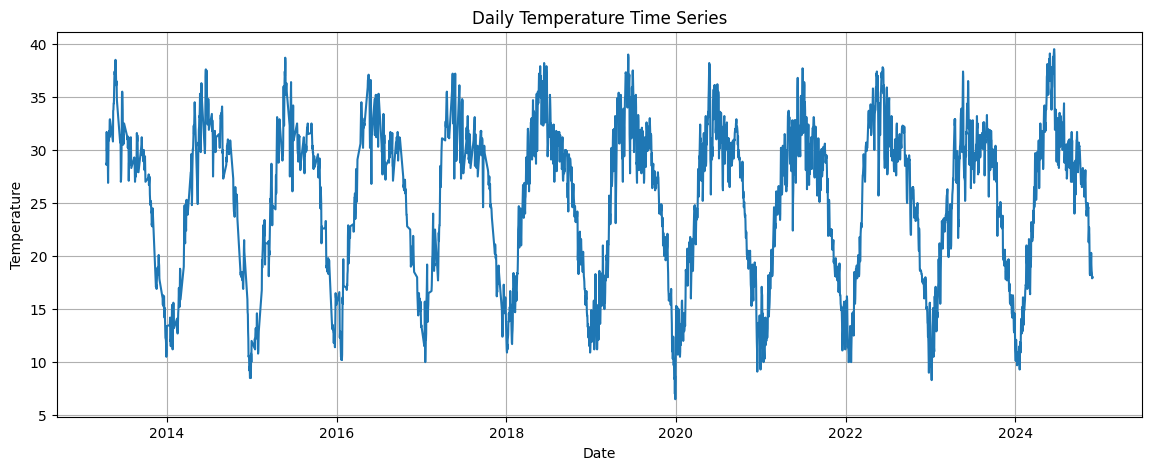

In [7]:
# Побудуйте графік зміни температури у часі
plt.figure(figsize=(14, 5))
plt.plot(df["temp"])
plt.title("Daily Temperature Time Series")
plt.xlabel("Date")
plt.ylabel("Temperature")
plt.grid()
plt.show()

Ковзне середнє

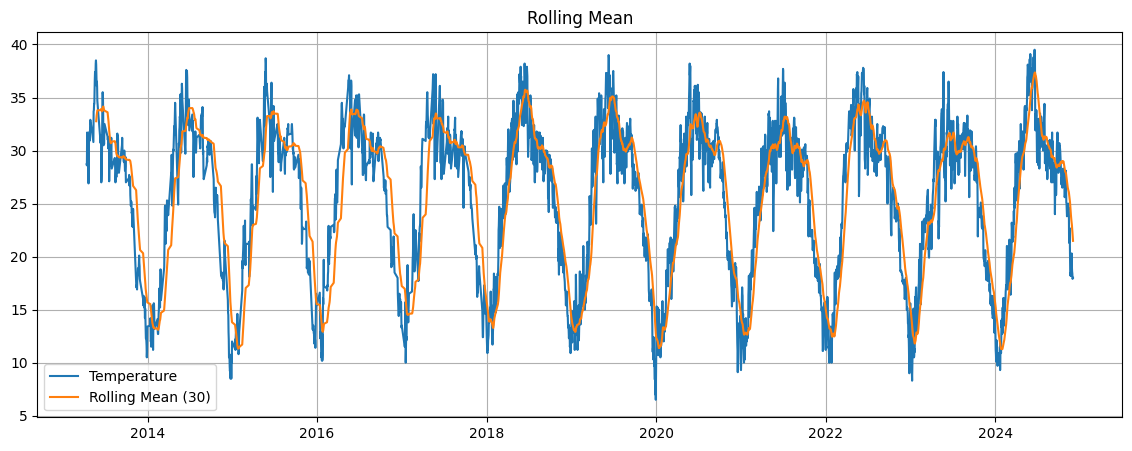

In [8]:
# Обчисліть та візуалізуйте ковзне середнє температури
df["rolling_mean"] = df["temp"].rolling(window=30).mean()

plt.figure(figsize=(14, 5))
plt.plot(df["temp"], label="Temperature")
plt.plot(df["rolling_mean"], label="Rolling Mean (30)")
plt.title("Rolling Mean")
plt.legend()
plt.grid()
plt.show()

Розподіл температури

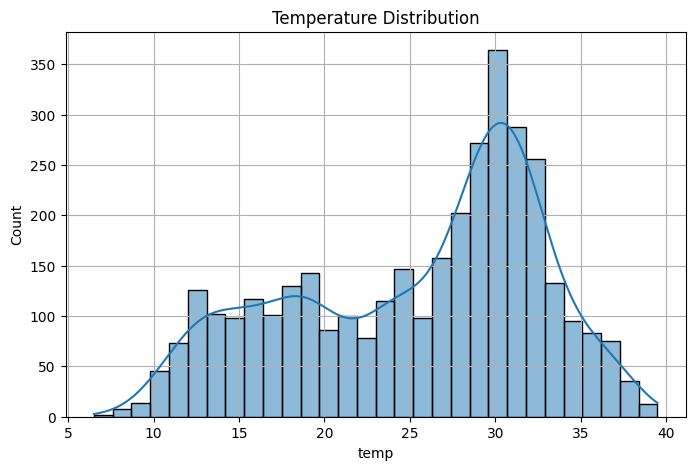

In [9]:
# Побудуйте гістограму розподілу температури
plt.figure(figsize=(8, 5))
sns.histplot(df["temp"], bins=30, kde=True)
plt.title("Temperature Distribution")
plt.grid()
plt.show()

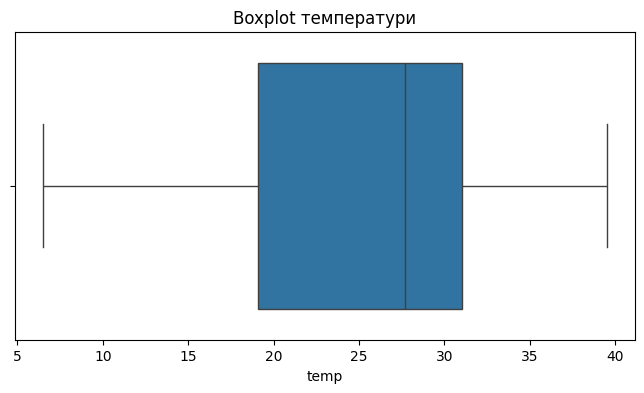

In [10]:
# Побудуйте boxplot температури для аналізу викидів
plt.figure(figsize=(8, 4))
sns.boxplot(x=df["temp"])
plt.title("Boxplot температури")
plt.show()

Аналіз автокореляції
ACF

PACF

<Figure size 1200x500 with 0 Axes>

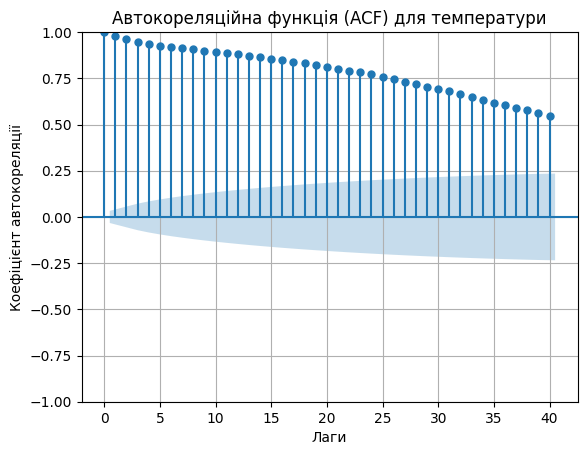

In [35]:
# Побудуйте графік автокореляційної функції (ACF)
plt.figure(figsize=(12, 5))
plot_acf(df["temp"].dropna(), lags=40, alpha=0.05)
plt.title("Автокореляційна функція (ACF) для температури")
plt.xlabel("Лаги")
plt.ylabel("Коефіцієнт автокореляції")
plt.grid(True)
plt.show()

Автокореляційна функція (ACF) використовується для аналізу залежності значень часового ряду від його попередніх значень. Вона відображає ступінь кореляції між значенням показника у певний момент часу та значеннями цього самого показника у попередні моменти часу, які називаються лагами. Побудова графіка автокореляційної функції дозволяє виявити, чи існує статистично значуща залежність між поточним значенням ряду та його попередніми спостереженнями. На такому графіку по горизонтальній осі відкладаються лаги, тобто кількість часових кроків назад, а по вертикальній — значення коефіцієнта автокореляції. Аналіз графіка ACF дає можливість виявити наявність тренду, сезонності або інших закономірностей у часовому ряді, а також використовується для визначення параметрів статистичних моделей прогнозування, зокрема моделі ARIMA.

<Figure size 1200x500 with 0 Axes>

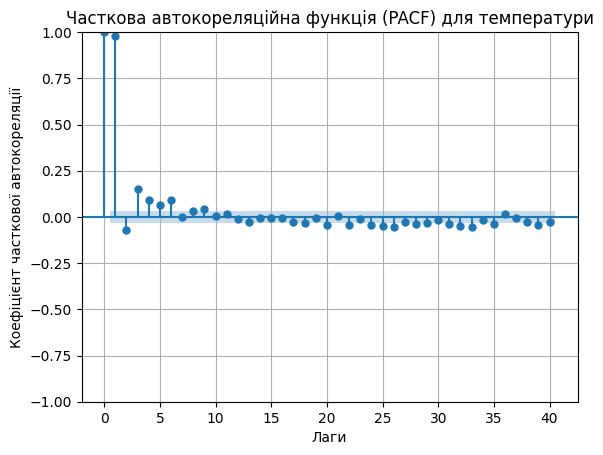

In [36]:
# Побудуйте графік часткової автокореляційної функції (PACF)
plt.figure(figsize=(12, 5))
plot_pacf(df["temp"].dropna(), lags=40, alpha=0.05, method='ywm')
plt.title("Часткова автокореляційна функція (PACF) для температури")
plt.xlabel("Лаги")
plt.ylabel("Коефіцієнт часткової автокореляції")
plt.grid(True)
plt.show()

Часткова автокореляційна функція (PACF) застосовується для більш точного визначення залежності між значеннями часового ряду. На відміну від звичайної автокореляційної функції, PACF вимірює кореляцію між значенням ряду у певний момент часу та значенням у попередній момент часу з конкретним лагом, усуваючи вплив усіх проміжних лагів. Таким чином, часткова автокореляція показує «чисту» залежність між двома спостереженнями часового ряду. Побудова графіка PACF дозволяє визначити, які саме лаги мають статистично значущий вплив на значення ряду. Це є важливим етапом під час побудови моделей прогнозування часових рядів, оскільки аналіз графіка часткової автокореляції використовується для визначення порядку авторегресійної складової моделі, зокрема параметра
𝑝
p у моделі ARIMA.

In [37]:
# Сформуйте цільовий часовий ряд та розділіть його на train/test у часовому порядку

y = df["temp"].dropna()

train_size = int(len(y) * 0.8)
train = y[:train_size]
test = y[train_size:]

print(f"Розмір тренувальної вибірки (train): {len(train)}")
print(f"Розмір тестової вибірки (test): {len(test)}")

Розмір тренувальної вибірки (train): 2845
Розмір тестової вибірки (test): 712


ARIMA

https://developer.ibm.com/tutorials/awb-arima-models-in-python/

In [42]:
# Побудуйте та навчіть модель ARIMA. Отримайте прогноз для тестової вибірки
df = df[~df.index.duplicated(keep='first')]
y = df["temp"].dropna()
train_size = int(len(y) * 0.8)
train = y[:train_size]
test = y[train_size:]

train = train.asfreq('D')
model = ARIMA(train, order=(1, 1, 1))
model_fit = model.fit()

predictions = model_fit.forecast(steps=len(test))
arima_pred = pd.Series(predictions, index=test.index)

In [43]:
# Виведіть статистичний звіт навченої ARIMA-моделі
print(model_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                   temp   No. Observations:                 3537
Model:                 ARIMA(1, 1, 1)   Log Likelihood               -4953.407
Date:                Thu, 15 Oct 2026   AIC                           9912.815
Time:                        21:23:34   BIC                           9931.327
Sample:                    04-14-2013   HQIC                          9919.418
                         - 12-19-2022                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.3892      0.100     -3.882      0.000      -0.586      -0.193
ma.L1          0.5098      0.095      5.374      0.000       0.324       0.696
sigma2         1.7998      0.034     53.611      0.0

сигма 2 : це представляє дисперсію залишкових значень, чим менше, тим краще

логарифмічна правдоподібність : це оцінка максимальної правдоподібності для моделі ARIMA, чим вище, тим краще

aic : міра ступеню відповідності та економності моделі, чим нижче, тим краще

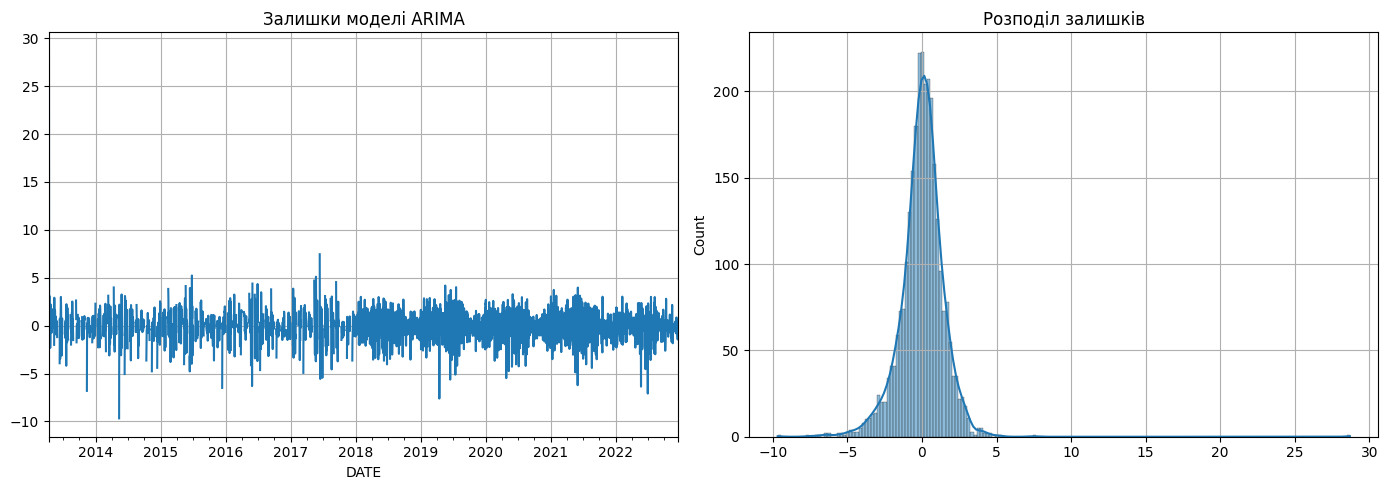

In [44]:
# Проаналізуйте залишки ARIMA-моделі та побудуйте відповідні графіки
residuals = model_fit.resid

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

residuals.plot(ax=axes[0], title="Залишки моделі ARIMA")
axes[0].grid(True)

sns.histplot(residuals, kde=True, ax=axes[1])
axes[1].set_title("Розподіл залишків")
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [45]:
# Реалізуйте MAPE та обчисліть MAE, RMSE, MAPE для ARIMA
def mean_absolute_percentage_error(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

arima_mae = mean_absolute_error(test, arima_pred)
arima_rmse = np.sqrt(mean_squared_error(test, arima_pred))
arima_mape = mean_absolute_percentage_error(test, arima_pred)

print(f"ARIMA MAE:  {arima_mae:.4f}")
print(f"ARIMA RMSE: {arima_rmse:.4f}")
print(f"ARIMA MAPE: {arima_mape:.4f}%")

ARIMA MAE:  11.3044
ARIMA RMSE: 12.9071
ARIMA MAPE: 40.7892%


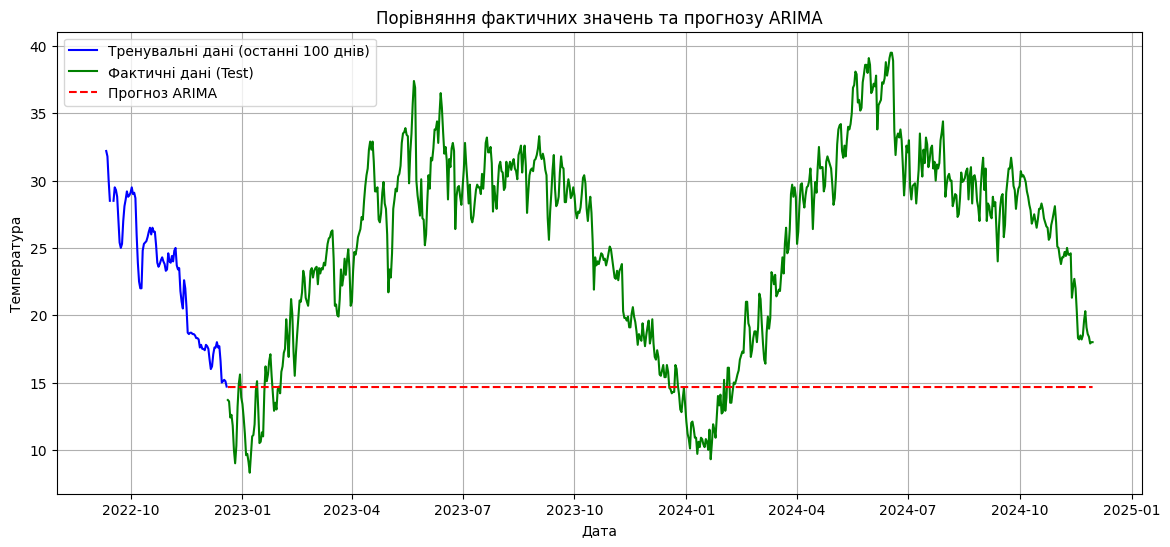

In [46]:
# Візуалізуйте фактичні значення та прогноз ARIMA
plt.figure(figsize=(14, 6))
plt.plot(train.index[-100:], train.values[-100:], label="Тренувальні дані (останні 100 днів)", color="blue")
plt.plot(test.index, test.values, label="Фактичні дані (Test)", color="green")
plt.plot(arima_pred.index, arima_pred.values, label="Прогноз ARIMA", color="red", linestyle="--")

plt.title("Порівняння фактичних значень та прогнозу ARIMA")
plt.xlabel("Дата")
plt.ylabel("Температура")
plt.legend()
plt.grid(True)
plt.show()

PROPHET

https://facebook.github.io/prophet/docs/quick_start.html

In [47]:
# Підготуйте дані у форматі, необхідному для Prophet
df_prophet = df.reset_index()[["DATE", "temp"]].rename(columns={"DATE": "ds", "temp": "y"})

train_prophet = df_prophet.iloc[:train_size]
test_prophet = df_prophet.iloc[train_size:]

In [48]:
# Створіть та навчіть модель Prophet
from prophet import Prophet

model_prophet = Prophet()
model_prophet.fit(train_prophet)

INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


Прогноз

In [49]:
# Побудуйте прогноз Prophet для тестового періоду
future = model_prophet.make_future_dataframe(periods=len(test_prophet))
forecast = model_prophet.predict(future)

prophet_pred = forecast.iloc[train_size:]["yhat"].values
prophet_pred_series = pd.Series(prophet_pred, index=test.index)

In [50]:
# Обчисліть MAE, RMSE, MAPE для Prophet
prophet_mae = mean_absolute_error(test, prophet_pred_series)
prophet_rmse = np.sqrt(mean_squared_error(test, prophet_pred_series))
prophet_mape = mean_absolute_percentage_error(test, prophet_pred_series)

print(f"Prophet MAE:  {prophet_mae:.4f}")
print(f"Prophet RMSE: {prophet_rmse:.4f}")
print(f"Prophet MAPE: {prophet_mape:.4f}%")

Prophet MAE:  2.0026
Prophet RMSE: 2.5877
Prophet MAPE: 9.0172%


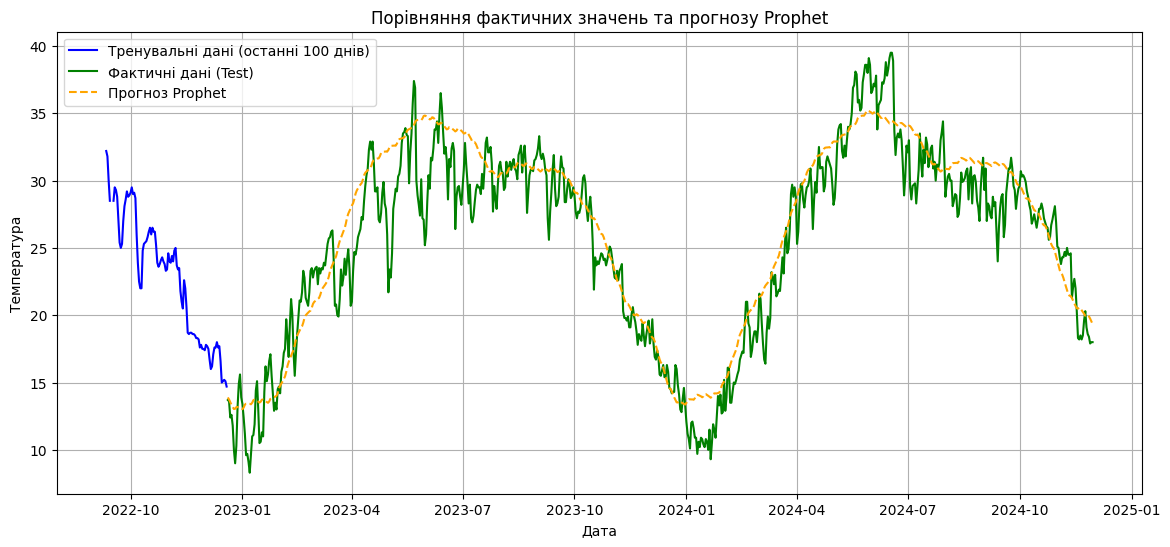

In [51]:
# Візуалізуйте фактичні значення та прогноз Prophet
plt.figure(figsize=(14, 6))
plt.plot(train.index[-100:], train.values[-100:], label="Тренувальні дані (останні 100 днів)", color="blue")
plt.plot(test.index, test.values, label="Фактичні дані (Test)", color="green")
plt.plot(test.index, prophet_pred_series.values, label="Прогноз Prophet", color="orange", linestyle="--")

plt.title("Порівняння фактичних значень та прогнозу Prophet")
plt.xlabel("Дата")
plt.ylabel("Температура")
plt.legend()
plt.grid(True)
plt.show()

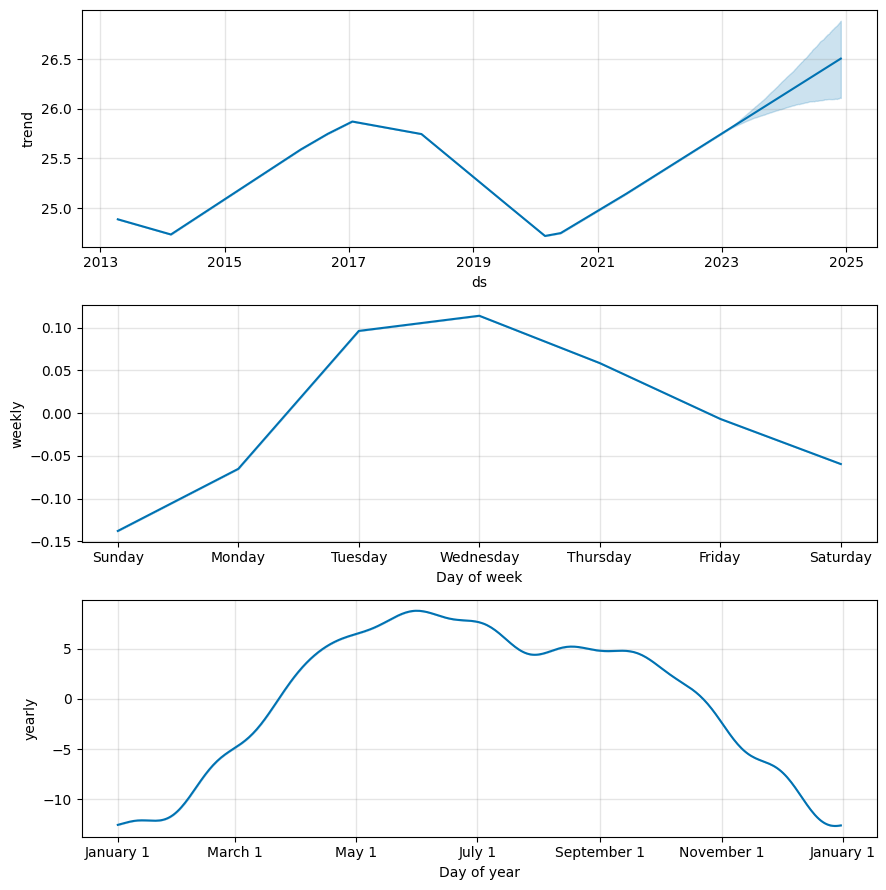

In [52]:
# Побудуйте компоненти моделі Prophet
fig1 = model_prophet.plot_components(forecast)
plt.show()

ПІДГОТОВКА ДАНИХ ДЛЯ LSTM

In [53]:
# Масштабуйте часовий ряд та сформуйте послідовності для LSTM

scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(y.values.reshape(-1, 1))

def create_sequences(dataset, time_step=60):
    X, y_seq = [], []
    for i in range(len(dataset) - time_step - 1):
        a = dataset[i:(i + time_step), 0]
        X.append(a)
        y_seq.append(dataset[i + time_step, 0])
    return np.array(X), np.array(y_seq)

time_step = 60
X, y_lstm = create_sequences(scaled_data, time_step)

X = X.reshape(X.shape[0], X.shape[1], 1)

In [54]:
# Розділіть послідовності на тренувальну та тестову вибірки без перемішування
train_lstm_size = int(len(X) * 0.8)

X_train, X_test = X[:train_lstm_size], X[train_lstm_size:]
y_train_lstm, y_test_lstm = y_lstm[:train_lstm_size], y_lstm[train_lstm_size:]

print(f"Форма X_train: {X_train.shape}")
print(f"Форма X_test: {X_test.shape}")

Форма X_train: (2796, 60, 1)
Форма X_test: (699, 60, 1)


In [55]:
# Побудуйте архітектуру LSTM-моделі та скомпілюйте її
model_lstm = Sequential([
    LSTM(50, return_sequences=True, input_shape=(X_train.shape[1], 1)),
    LSTM(50, return_sequences=False),
    Dense(25),
    Dense(1)
])

model_lstm.compile(optimizer='adam', loss='mean_squared_error')

In [57]:
# Навчіть LSTM-модель
history = model_lstm.fit(
    X_train, y_train_lstm,
    epochs=20,
    batch_size=32,
    validation_data=(X_test, y_test_lstm),
    verbose=1
)

Epoch 1/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0019 - val_loss: 0.0016
Epoch 2/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0019 - val_loss: 0.0016
Epoch 3/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0021 - val_loss: 0.0019
Epoch 4/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0018 - val_loss: 0.0016
Epoch 5/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0018 - val_loss: 0.0015
Epoch 6/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0020 - val_loss: 0.0021
Epoch 7/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0019 - val_loss: 0.0016
Epoch 8/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0018 - val_loss: 0.0018
Epoch 9/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0018 - val_loss: 0.0020
Epoch 10/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0019 - val_loss: 0.0016
Epoch 11/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0018 - val_loss: 0.0017
Epoch 12/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0

In [58]:
# Виведіть структуру LSTM-моделі
model_lstm.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 60, 50)         │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 25)             │         1,275 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 95,705 (373.85 KB)

 Trainable params: 31,901 (124.61 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 63,804 (249.24 KB)

In [59]:
# Отримайте прогноз LSTM та виконайте зворотне масштабування
train_predict = model_lstm.predict(X_train)
test_predict = model_lstm.predict(X_test)

test_predict_rescaled = scaler.inverse_transform(test_predict)
y_test_lstm_rescaled = scaler.inverse_transform(y_test_lstm.reshape(-1, 1))

88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step


In [61]:
# Сформуйте часові мітки для тестового прогнозу LSTM
test_dates = test.index[-len(test_predict_rescaled):]

lstm_pred_series = pd.Series(test_predict_rescaled.flatten(), index=test_dates)
y_test_lstm_series = pd.Series(y_test_lstm_rescaled.flatten(), index=test_dates)

In [62]:
# Обчисліть MAE, RMSE, MAPE для LSTM
lstm_mae = mean_absolute_error(y_test_lstm_series, lstm_pred_series)
lstm_rmse = np.sqrt(mean_squared_error(y_test_lstm_series, lstm_pred_series))
lstm_mape = mean_absolute_percentage_error(y_test_lstm_series, lstm_pred_series)

print(f"LSTM MAE:  {lstm_mae:.4f}")
print(f"LSTM RMSE: {lstm_rmse:.4f}")
print(f"LSTM MAPE: {lstm_mape:.4f}%")

LSTM MAE:  1.0958
LSTM RMSE: 1.3807
LSTM MAPE: 4.5426%


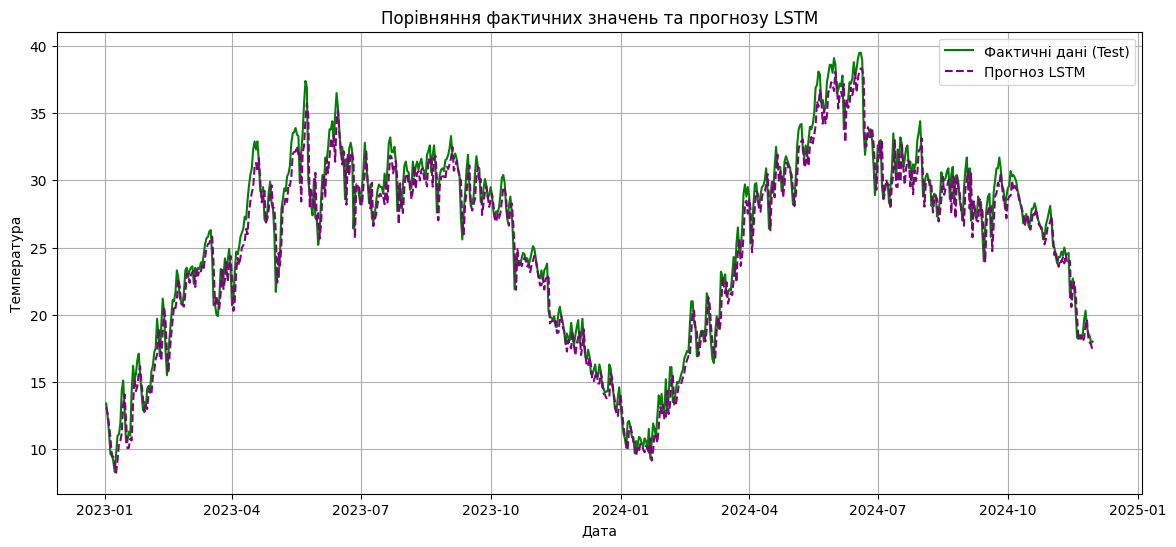

In [63]:
# Візуалізуйте фактичні значення та прогноз LSTM
plt.figure(figsize=(14, 6))
plt.plot(y_test_lstm_series.index, y_test_lstm_series.values, label="Фактичні дані (Test)", color="green")
plt.plot(lstm_pred_series.index, lstm_pred_series.values, label="Прогноз LSTM", color="purple", linestyle="--")

plt.title("Порівняння фактичних значень та прогнозу LSTM")
plt.xlabel("Дата")
plt.ylabel("Температура")
plt.legend()
plt.grid(True)
plt.show()

Порівняння моделей

In [64]:
# Створіть підсумкову таблицю MAE, RMSE, MAPE для ARIMA, Prophet та LSTM
# Порівняйте моделі за отриманими результатами
comparison_df = pd.DataFrame({
    'Модель': ['ARIMA', 'Prophet', 'LSTM'],
    'MAE': [arima_mae, prophet_mae, lstm_mae],
    'RMSE': [arima_rmse, prophet_rmse, lstm_rmse],
    'MAPE (%)': [arima_mape, prophet_mape, lstm_mape]
}).set_index('Model' if 'Model' in locals() else 'Модель')

display(comparison_df)

,MAE,RMSE,MAPE (%)
Модель,,,
ARIMA,11.304426,12.907085,40.789237
Prophet,2.002565,2.587654,9.017190
LSTM,1.095798,1.380728,4.542557


## Висновок

Сформулюйте висновок за результатами роботи: коротко охарактеризуйте виконаний аналіз, порівняйте моделі ARIMA, Prophet та LSTM за метриками MAE, RMSE і MAPE та зазначте, яка модель продемонструвала найкращу якість прогнозування.


Протягом виконання даної лабораторної роботи було проведено повний цикл аналізу та прогнозування щоденних кліматичних даних (температури) за допомогою трьох різних моделей: ARIMA, Prophet та LSTM.

Було виконано попередню обробку даних, побудовано графіки розподілу, ковзного середнього, а також функції автокореляції (ACF) і часткової автокореляції (PACF), що дозволило виявити закономірності та сезонні коливання в часовому ряді.

Порівняння моделей за метриками:

ARIMA: продемонструвала найнижчу точність для цього набору даних — MAE = 11.30, RMSE = 12.91, MAPE = 40.79%.

Prophet: показала значно кращі результати завдяки вбудованому обліку сезонності — MAE = 2.00, RMSE = 2.59, MAPE = 9.02%.

LSTM: забезпечила найкращу якість прогнозування серед усіх розглянутих моделей завдяки здатності нейронної мережі ефективно моделювати нелінійні послідовні залежності — MAE = 1.10, RMSE = 1.38, MAPE = 4.54%.

Найкращу якість прогнозування продемонструвала нейронна мережа LSTM, яка забезпечила мінімальні значення похибок (зокрема найнижчий показник MAPE на рівні 4.54%).